In [2]:
import tensorflow as tf
# from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import seaborn as sns
tf.random.set_seed(42)
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 3us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 75s 3us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 9s 2us/step


In [4]:
print("Dimensions du train set :", X_train.shape)
print("Dimensions du test set :", X_test.shape)
print("Type des pixels :", X_train.dtype)
print("Valeurs min/max :", X_train.min(), X_train.max())

Dimensions du train set : (60000, 28, 28)
Dimensions du test set : (10000, 28, 28)
Type des pixels : uint8
Valeurs min/max : 0 255


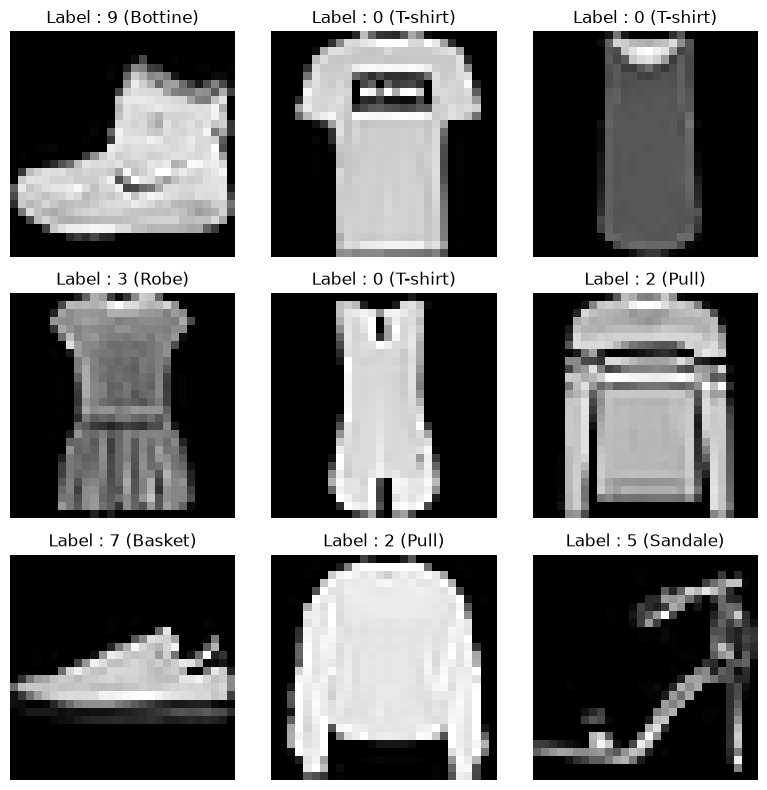

In [5]:

class_names = ['T-shirt', 'Pantalon', 'Pull', 'Robe', 'Manteau',
               'Sandale', 'Chemise', 'Basket', 'Sac', 'Bottine']

plt.figure(figsize=(8, 8))
for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label : {y_train[i]} ({class_names[y_train[i]]})")
    plt.axis('off')
plt.tight_layout()
plt.show()

<h2>Que remarquez-vous sur la nature des données et la taille des images ?
<h4>
Ce sont des images de vêtements en niveaux de gris, de taille 28 × 28 avec un seul canal, donc identiques à MNIST en format.  

Les pixels sont des entiers uint8 entre 0 et 255.  

Les classes sont bien plus difficiles à distinguer que des chiffres : T-shirt, chemise, pull et manteau se ressemblent  
  beaucoup, avec peu de pixels pour les différencier.  

Les classes sont équilibrées : 6 000 images par classe dans le train.  


In [6]:
from tensorflow.keras.utils import to_categorical

# Normalisation des pixels entre 0 et 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Encodage one-hot des labels
y_train_cat = to_categorical(y_train, 10)
y_test_cat = to_categorical(y_test, 10)

print("Exemple de label :", y_train[0])
print("Après one-hot :", y_train_cat[0])

Exemple de label : 9
Après one-hot : [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


<h2>1. Pourquoi faut-il normaliser les images ?
<h4>
Les valeurs entre 0 et 1 sont à la même échelle que les poids initiaux, ce qui évite de grands gradients.
L’optimiseur converge plus vite et de façon plus stable.
Sans normalisation, la perte peut osciller, ou le modèle apprendre beaucoup plus lentement.
<h2>
2. Importance du one-hot encoding en classification multiclasse ?
<h4>
Il transforme un label entier (ex. 3) en vecteur de 10 valeurs avec un seul 1 : [0,0,0,1,0,0,0,0,0,0].

In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout

model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    X_train, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

Epoch 1/10


W0000 00:00:1792862583.771192  164484 cpu_allocator_impl.cc:174] Allocation of 150528000 exceeds 10% of free system memory.


368/375 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7793 - loss: 0.6258

W0000 00:00:1792862587.137184  164484 cpu_allocator_impl.cc:174] Allocation of 37632000 exceeds 10% of free system memory.


375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.7800 - loss: 0.6233 - val_accuracy: 0.8397 - val_loss: 0.4485
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8451 - loss: 0.4294 - val_accuracy: 0.8554 - val_loss: 0.3976
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8589 - loss: 0.3872 - val_accuracy: 0.8643 - val_loss: 0.3751
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8678 - loss: 0.3611 - val_accuracy: 0.8739 - val_loss: 0.3535
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8748 - loss: 0.3406 - val_accuracy: 0.8782 - val_loss: 0.3414
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8791 - loss: 0.3279 - val_accuracy: 0.8767 - val_loss: 0.3474
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8829 - loss: 0.3186 - val_accuracy: 0.8802 - val_loss: 0.3374
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.8868 - loss: 0.3044 - val_accuracy: 0.8823 - val_

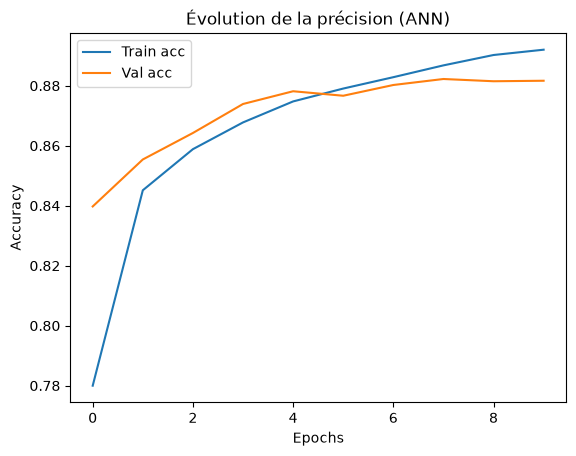

In [9]:
plt.plot(history.history['accuracy'], label='Train acc')
plt.plot(history.history['val_accuracy'], label='Val acc')
plt.legend()
plt.title('Évolution de la précision (ANN)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

<h1>1. Pourquoi utilise-t-on ReLU ici ?
<h4>
max(0, x) est très simple à calculer, donc rapide.  

Son gradient vaut 1 pour x > 0 : il ne s’écrase pas, ce qui limite la disparition du gradient (contrairement à sigmoïde et tanh).  

Il apporte la non-linéarité nécessaire pour apprendre des formes complexes.  

C’est le choix par défaut standard pour les couches cachées.  
<h1>2. Différence entre accuracy et val_accuracy ?
<h4>
Pourquoi les comparer ? Si accuracy ≫ val_accuracy, le modèle mémorise : c’est du surapprentissage. 
<h1>3. Que se passe-t-il avec 50 époques ?
<h4>
accuracy continue de monter, vers 95 à 97 %.  

val_accuracy plafonne vers 88 à 90 %, puis stagne ou baisse.  

La perte de validation remonte : c’est le surapprentissage.  

L’écart entre train et validation s’agrandit.  

Remède : EarlyStopping, plus de Dropout, ou un CNN.

In [10]:
test_loss, test_acc = model.evaluate(X_test, y_test_cat)
print("Précision sur le test set :", test_acc)

  1/313 ━━━━━━━━━━━━━━━━━━━━ 35s 113ms/step - accuracy: 0.8750 - loss: 0.2857

W0000 00:00:1792864155.233612  164484 cpu_allocator_impl.cc:174] Allocation of 31360000 exceeds 10% of free system memory.


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8734 - loss: 0.3589
Précision sur le test set : 0.8733999729156494


W0000 00:00:1792864211.240315  164484 cpu_allocator_impl.cc:174] Allocation of 150528000 exceeds 10% of free system memory.
W0000 00:00:1792864214.451085  164484 cpu_allocator_impl.cc:174] Allocation of 37632000 exceeds 10% of free system memory.


{'sigmoid': 0.8654166460037231, 'tanh': 0.8744999766349792, 'relu': 0.875333309173584, 'LeakyReLU': 0.8734999895095825}


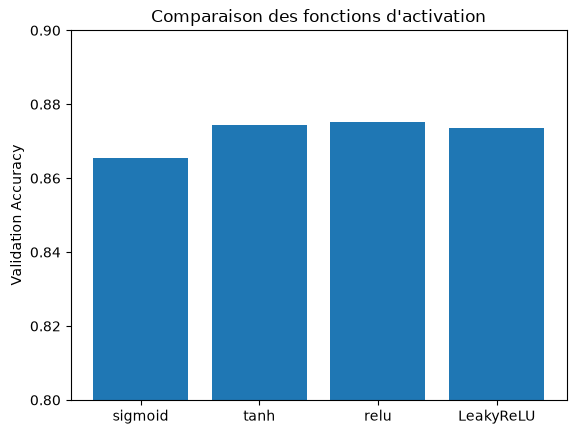

In [ ]:
from tensorflow.keras.layers import LeakyReLU

activations = ['sigmoid', 'tanh', 'relu']
results = {}

for act in activations:
    model_act = Sequential([
        Input(shape=(28, 28)),
        Flatten(),
        Dense(128, activation=act),
        Dense(64, activation=act),
        Dense(10, activation='softmax')
    ])
    model_act.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
    h = model_act.fit(X_train, y_train_cat, epochs=5, batch_size=128,
                      validation_split=0.2, verbose=0)
    results[act] = h.history['val_accuracy'][-1]

# Leaky ReLU 
model_leaky = Sequential([
    Input(shape=(28, 28)),
    Flatten(),
    Dense(128),
    LeakyReLU(0.1),
    Dense(64),
    LeakyReLU(0.1),
    Dense(10, activation='softmax')
])
model_leaky.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
h = model_leaky.fit(X_train, y_train_cat, epochs=5, batch_size=128,
                    validation_split=0.2, verbose=0)
results['LeakyReLU'] = h.history['val_accuracy'][-1]

print(results)

plt.bar(list(results.keys()), list(results.values()))
plt.title("Comparaison des fonctions d'activation")
plt.ylabel("Validation Accuracy")
plt.ylim(0.80, 0.90)   
plt.show()

<h1>1. Quelle fonction donne les meilleurs résultats ?
<h4>>En général ReLU et LeakyReLU, avec un petit avantage sur sigmoïde et tanh. Les écarts sont faibles avec seulement 5 époques, donc note ce que tu observes. Sigmoïde est souvent la dernière : elle apprend plus lentement.
<h1>
2. Pourquoi sigmoïde et tanh sont moins utilisées dans les couches cachées ?
<h4>
Elles saturent : pour de grandes valeurs positives ou négatives, la courbe devient plate et le gradient tend vers 0.
Résultat : le problème de disparition du gradient. Les premières couches reçoivent des gradients minuscules et apprennent très lentement, surtout dans les réseaux profonds.
Elles demandent aussi un calcul d’exponentielles, plus coûteux que max(0, x).
Sigmoïde n’est pas centrée sur 0 (sortie entre 0 et 1). Tanh l’est (sortie entre -1 et 1), ce qui explique qu’elle fasse un peu mieux.

Où les utilise-t-on encore ? Sigmoïde en sortie pour une classification binaire, tanh dans certains réseaux récurrents.
<h1>
3. À quoi sert LeakyReLU ?
<h4>
ReLU renvoie 0 pour toute valeur négative, donc le gradient est nul. Un neurone qui ne reçoit que des valeurs négatives ne apprend plus jamais : c’est le « dying ReLU » (neurone mort). LeakyReLU laisse passer une petite pente pour les négatifs (0,1 × x ici), donc le gradient n’est jamais totalement nul et le neurone peut se « réveiller ».

In [ ]:
from tensorflow.keras.layers import Conv2D, MaxPooling2D


X_train_cnn = X_train.reshape(-1, 28, 28, 1)
X_test_cnn = X_test.reshape(-1, 28, 28, 1)

cnn = Sequential([
    Input(shape=(28, 28, 1)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.3),
    Dense(10, activation='softmax')
])

cnn.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cnn.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
history_cnn = cnn.fit(
    X_train_cnn, y_train_cat,
    epochs=10,
    batch_size=128,
    validation_split=0.2
)

test_loss, test_acc = cnn.evaluate(X_test_cnn, y_test_cat)
print("Précision CNN sur test set :", test_acc)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 19s 48ms/step - accuracy: 0.7689 - loss: 0.6384 - val_accuracy: 0.8538 - val_loss: 0.4001
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 19s 50ms/step - accuracy: 0.8581 - loss: 0.3994 - val_accuracy: 0.8744 - val_loss: 0.3435
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 16s 44ms/step - accuracy: 0.8757 - loss: 0.3449 - val_accuracy: 0.8847 - val_loss: 0.3111
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 19s 52ms/step - accuracy: 0.8857 - loss: 0.3172 - val_accuracy: 0.8866 - val_loss: 0.3047
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 21s 57ms/step - accuracy: 0.8934 - loss: 0.2924 - val_accuracy: 0.8882 - val_loss: 0.2959
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 21s 57ms/step - accuracy: 0.9002 - loss: 0.2741 - val_accuracy: 0.8924 - val_loss: 0.2916
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 22s 57ms/step - accuracy: 0.9045 - loss: 0.2591 - val_accuracy: 0.8984 - val_loss: 0.2765
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 21s 57ms/step - accuracy: 0.9099 - loss: 0.2449 - 

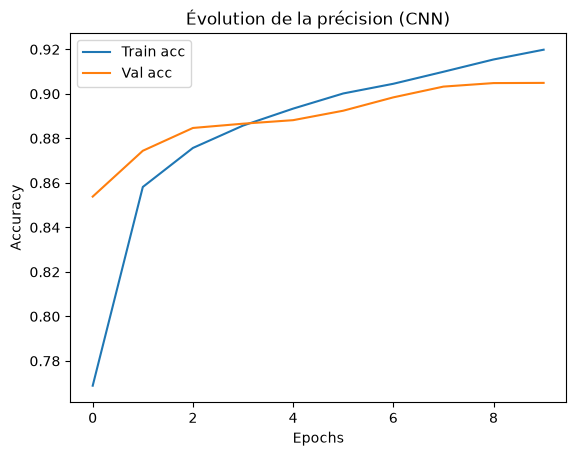

In [14]:
plt.plot(history_cnn.history['accuracy'], label='Train acc')
plt.plot(history_cnn.history['val_accuracy'], label='Val acc')
plt.legend()
plt.title('Évolution de la précision (CNN)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.show()

<h2>2. Pourquoi le CNN donne-t-il de meilleurs résultats ?
<h4>
Il détecte des motifs locaux : bords, textures, coins. Les couches suivantes les combinent en formes (manche, col, semelle).
Le partage des poids fait qu’un motif est reconnu où qu’il soit dans l’image (invariance à la translation).
Il a moins de paramètres par fonction utile, donc généralise mieux.

Analogie : l’ANN lit l’image comme une liste de 784 nombres en désordre. Le CNN la regarde comme une vraie image avec une loupe qu’on promène dessus.

<h2>3. Rôle des couches de Pooling ?
<h4>
MaxPooling2D((2,2)) garde la valeur maximale de chaque bloc 2×2.
<h4>
Elle réduit la taille (÷ 2), donc moins de calcul et moins de paramètres.
<h4>
Elle rend le modèle plus robuste aux petits décalages.
<h4>
Elle conserve l’information la plus marquante (le motif détecté le plus fort).
<h4>
Elle n’a aucun paramètre à apprendre.


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step


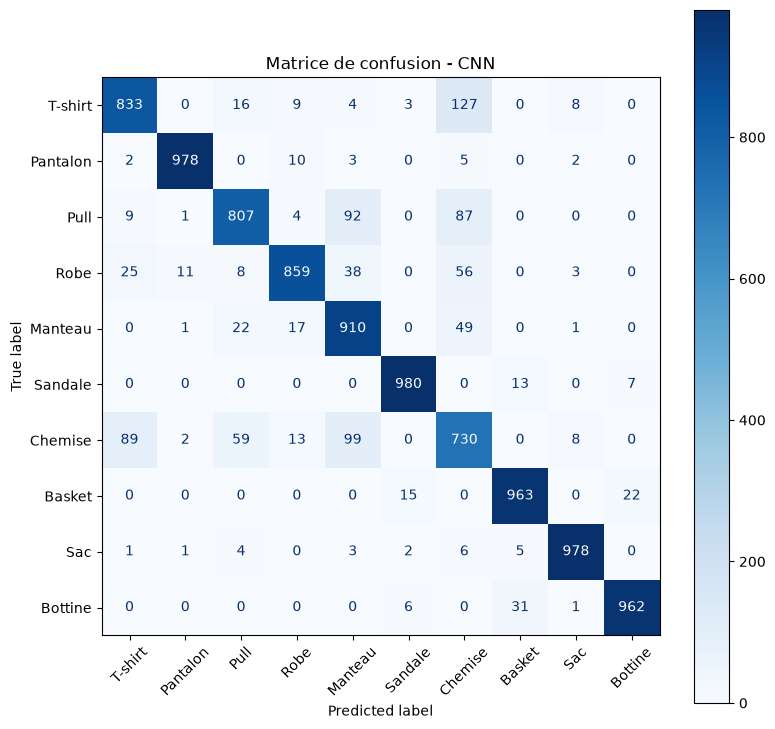

In [15]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import numpy as np

y_pred = np.argmax(cnn.predict(X_test_cnn), axis=1)

fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, cmap="Blues",
    display_labels=class_names, xticks_rotation=45, ax=ax
)
plt.title("Matrice de confusion - CNN")
plt.show()

In [ ]:
cm = confusion_matrix(y_test, y_pred)
np.fill_diagonal(cm, 0)   
for _ in range(3):
    i, j = np.unravel_index(cm.argmax(), cm.shape)
    print(f"{class_names[i]} pris pour {class_names[j]} : {cm[i, j]} fois")
    cm[i, j] = 0

T-shirt pris pour Chemise : 127 fois
Chemise pris pour Manteau : 99 fois
Pull pris pour Manteau : 92 fois


<h1>1. Quelles classes sont le plus souvent confondues ?
<h4>Typiquement : Chemise ↔ T-shirt, Chemise ↔ Pull, Pull ↔ Manteau. La Chemise (6) est la classe la plus difficile, avec souvent seulement 65 à 75 % de réussite. À l’inverse, Pantalon, Sac, Basket et Bottine sont presque toujours bien reconnus.

<h1>2. Comment réduire ces erreurs ?
<h4>
Data Augmentation  
 

Un CNN plus profond, avec plus de filtres  

BatchNormalization et un peu plus d’époques avec EarlyStopping  

Un réglage des hyperparamètres (taux d’apprentissage, Dropout)  

Des images en plus haute résolution (impossible ici, mais c’est la vraie cause du problème)  


In [17]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    horizontal_flip=True
)

datagen.fit(X_train_cnn)

history_aug = cnn.fit(
    datagen.flow(X_train_cnn, y_train_cat, batch_size=128),
    epochs=10,
    validation_data=(X_test_cnn, y_test_cat)
)

Epoch 1/10


I0000 00:00:1792865622.378643  164484 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


469/469 ━━━━━━━━━━━━━━━━━━━━ 38s 79ms/step - accuracy: 0.8589 - loss: 0.3938 - val_accuracy: 0.9019 - val_loss: 0.2806
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 36s 71ms/step - accuracy: 0.8781 - loss: 0.3334 - val_accuracy: 0.9030 - val_loss: 0.2672
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 39s 84ms/step - accuracy: 0.8854 - loss: 0.3135 - val_accuracy: 0.9032 - val_loss: 0.2706
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 42s 88ms/step - accuracy: 0.8877 - loss: 0.3034 - val_accuracy: 0.9008 - val_loss: 0.2735
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 33s 70ms/step - accuracy: 0.8931 - loss: 0.2927 - val_accuracy: 0.8975 - val_loss: 0.2835
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 39s 83ms/step - accuracy: 0.8941 - loss: 0.2866 - val_accuracy: 0.9025 - val_loss: 0.2587
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 41s 87ms/step - accuracy: 0.8973 - loss: 0.2788 - val_accuracy: 0.9068 - val_loss: 0.2561
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 42s 89ms/step - accuracy: 0.8995 - loss: 0.2699 - val_accurac

<h1>1. Quel est l’intérêt de la Data Augmentation ?
<h4>
Elle augmente artificiellement la quantité et la variété des données d’entraînement.  

Elle réduit le surapprentissage : le modèle ne peut pas mémoriser des images toujours différentes.  

Elle rend le modèle robuste aux petites variations (position, angle, taille) qu’on rencontre dans la réalité.  

Elle ne coûte rien en collecte de données.  
